# Demand Forecasting Models

- **Goal**: Implement point and quantile forecasting models informed by the EDA insights, evaluated with rolling-origin time-series cross-validation.
- **Inputs**: `data/inventory_demand_forecasting.csv`
- **Outputs**: `outputs/csv/demand_forecasts.csv`, supporting files for the inventory notebook (`ratio_quantiles.csv`, `training_error_scale.csv`, `mean_forecast_lookahead.csv`, all in `outputs/csv/`), comparison tables (`point_model_comparison.csv`, `quantile_method_comparison.csv`) and figures in `outputs/figures/`

## 0. Setup and Data Loading

**Assumptions used throughout**
- The promotion calendar is known in advance, so `promotion` is a legitimate input when forecasting.
- `demand` is treated as unconstrained demand (see EDA: `stock` does not cap it).
- Each fold fits on data before the cut-off and forecasts the next 60 days; no information from the test window is used.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "utils.py").exists())
sys.path.insert(0, str(ROOT))   # lets `from src.utils import ...` work from notebooks/ or the project root
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge, PoissonRegressor, QuantileRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

from src.utils import (
    load_data, add_calendar_features, add_fourier_terms,
    rolling_origin_splits,
    point_metrics, pinball_loss, interval_coverage,
    save_output, save_figure,
    set_plot_style, MONTH_ORDER,
)

set_plot_style()

N_FOLDS, HORIZON, MIN_TRAIN_DAYS = 6, 60, 365
QUANTILES = [0.10, 0.50, 0.80, 0.90, 0.95]
RATIO_LEVELS = np.round(np.arange(0.01, 1.0, 0.01), 2)   # fine quantile grid of actual / fitted, exported for simulation
LOOKAHEAD = 21                                           # days of mean forecast exported beyond each test window

data = load_data()
cal = add_calendar_features(data)
print(f"Dataset loaded: {data.shape[0]} rows, {data['product_id'].nunique()} products across {data['date'].nunique()} days.")
data.head()

Dataset loaded: 3650 rows, 5 products across 730 days.


,date,product_id,category,price,promotion,stock,demand
0,2023-01-01,A,Electronics,116,1,121,95
1,2023-01-02,A,Electronics,199,0,495,85
2,2023-01-03,A,Electronics,17,0,480,76
3,2023-01-04,A,Electronics,197,0,429,80
4,2023-01-05,A,Electronics,160,0,111,66


## 1. Time-Series Validation Strategy

To guard against temporal data leakage and respect annual seasonality, we use Rolling-Origin (Expanding Window) Cross-Validation:
- **Number of folds**: 6 folds
- **Forecast horizon**: 60 days per fold
- **Minimum training window**: 365 days (every fold sees at least one complete annual cycle)
- **Cut-offs**: shared across all products via `rolling_origin_splits()`

With 730 days of data, 4 folds would only test May–December 2024 and miss the March–April peak season. Six folds of 60 days cover almost all of 2024 (from 6 January), at the cost of a shorter training window in the first fold.

In [2]:
splits = list(rolling_origin_splits(data, n_folds=N_FOLDS, horizon=HORIZON, min_train_days=MIN_TRAIN_DAYS))

print(f"Total CV folds: {len(splits)}\n")
for fold, train_idx, test_idx in splits:
    tr_d, te_d = data.loc[train_idx, 'date'], data.loc[test_idx, 'date']
    print(f"Fold {fold}: Train {tr_d.min().date()} -> {tr_d.max().date()} ({tr_d.nunique()} days) | "
          f"Test {te_d.min().date()} -> {te_d.max().date()} ({len(test_idx)} rows)")

Total CV folds: 6

Fold 1: Train 2023-01-01 -> 2024-01-05 (370 days) | Test 2024-01-06 -> 2024-03-05 (300 rows)
Fold 2: Train 2023-01-01 -> 2024-03-05 (430 days) | Test 2024-03-06 -> 2024-05-04 (300 rows)
Fold 3: Train 2023-01-01 -> 2024-05-04 (490 days) | Test 2024-05-05 -> 2024-07-03 (300 rows)
Fold 4: Train 2023-01-01 -> 2024-07-03 (550 days) | Test 2024-07-04 -> 2024-09-01 (300 rows)
Fold 5: Train 2023-01-01 -> 2024-09-01 (610 days) | Test 2024-09-02 -> 2024-10-31 (300 rows)
Fold 6: Train 2023-01-01 -> 2024-10-31 (670 days) | Test 2024-11-01 -> 2024-12-30 (300 rows)


## 2. Feature Engineering

Following the **EDA modelling decisions**:
1. **Annual seasonality**: smooth Fourier terms (K=3) via `add_fourier_terms()`; **no day-of-week** features (no weekly cycle found).
2. **Promotion flag**: key demand driver (+48% lift).
3. **Product pooling**: one-hot `product_id` so one model serves all five similar products.
4. **Trend term**: years since the start of the data, to test the ~7% year-over-year increase through CV.
5. **Dropped**: `price` and `stock` (confirmed by ablation in Section 4) and demand lags (no residual autocorrelation in the EDA).

In [3]:
def prepare_features(df, fourier_order=3, include_trend=True, extra_cols=None, month_dummies=False):
    """Build feature matrix X and target y following the EDA decisions."""
    feat = add_calendar_features(df)
    feat = add_fourier_terms(feat, order=fourier_order, period=365.25)

    product_dummies = pd.get_dummies(feat['product_id'], prefix='prod').astype(float)
    if month_dummies:
        seasonal = pd.get_dummies(feat['month'], prefix='month', drop_first=True).astype(float)
    else:
        seasonal = feat[[c for c in feat.columns if c.startswith('annual_')]]

    X = pd.concat([feat[['promotion']].astype(float), seasonal, product_dummies], axis=1)
    if include_trend:
        X['trend'] = (feat['date'] - feat['date'].min()).dt.days / 365.25   # years since start (0 to 2)
    for col in (extra_cols or []):
        X[col] = feat[col].astype(float)
    return X, feat['demand']

X, y = prepare_features(data)
print(f"Feature matrix X shape: {X.shape}")
print("Feature columns:", list(X.columns))

Feature matrix X shape: (3650, 13)
Feature columns: ['promotion', 'annual_sin_1', 'annual_cos_1', 'annual_sin_2', 'annual_cos_2', 'annual_sin_3', 'annual_cos_3', 'prod_A', 'prod_B', 'prod_C', 'prod_D', 'prod_E', 'trend']


### 2.1 Structure check: additive or multiplicative?

The EDA showed that promotion days are more volatile. Before choosing models, we check whether effects and noise scale with the demand level.

Promotion lift by month: min 1.42, max 1.61, mean 1.50
CV (std/mean) across month x promotion groups: min 0.36, max 0.46
Correlation between group mean and group std: 0.98


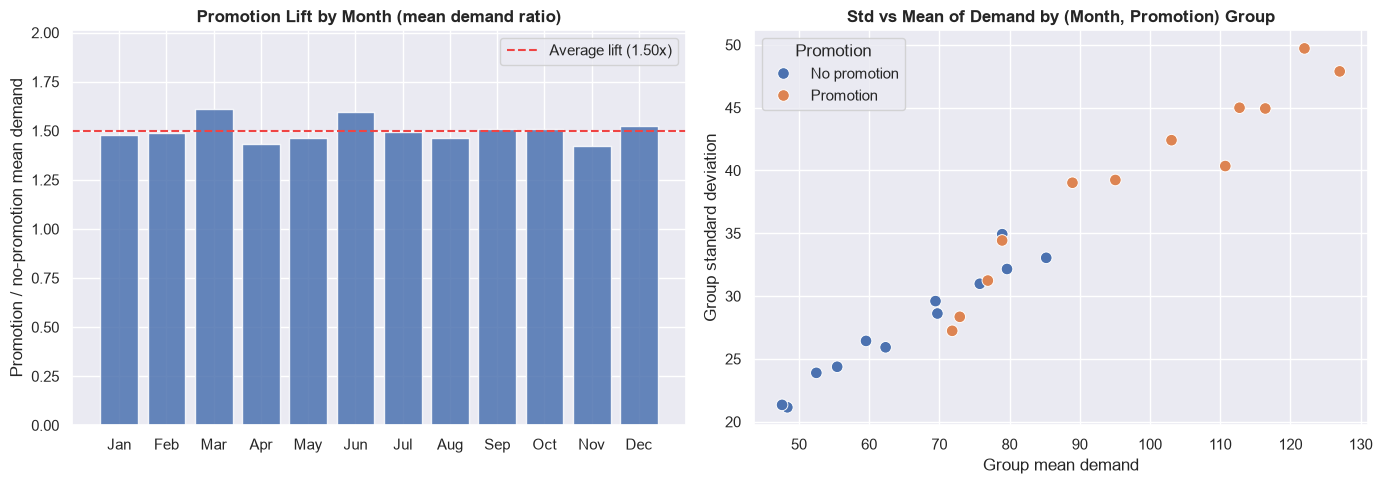

In [4]:
grp = cal.groupby(['month', 'promotion'])['demand'].agg(['mean', 'std']).reset_index()
grp['cv'] = grp['std'] / grp['mean']
wide = grp.pivot(index='month', columns='promotion', values='mean')
lift = wide[1] / wide[0]

print(f"Promotion lift by month: min {lift.min():.2f}, max {lift.max():.2f}, mean {lift.mean():.2f}")
print(f"CV (std/mean) across month x promotion groups: min {grp['cv'].min():.2f}, max {grp['cv'].max():.2f}")
print(f"Correlation between group mean and group std: {grp['mean'].corr(grp['std']):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(MONTH_ORDER, lift.values, alpha=0.85)
axes[0].axhline(lift.mean(), color='#ef4444', linestyle='--', label=f'Average lift ({lift.mean():.2f}x)')
axes[0].set_ylim(0, lift.max() * 1.25)
axes[0].set_title('Promotion Lift by Month (mean demand ratio)', fontweight='bold')
axes[0].set_ylabel('Promotion / no-promotion mean demand')
axes[0].legend()

sns.scatterplot(data=grp.assign(Promotion=grp['promotion'].map({0: 'No promotion', 1: 'Promotion'})),
                x='mean', y='std', hue='Promotion', s=70, ax=axes[1])
axes[1].set_title('Std vs Mean of Demand by (Month, Promotion) Group', fontweight='bold')
axes[1].set_xlabel('Group mean demand')
axes[1].set_ylabel('Group standard deviation')

plt.tight_layout()
save_figure(fig, '02_multiplicative_structure')
plt.show()

**Observations**
- Promotion lifts demand by about 1.5x in every month (range 1.42–1.61), not by a fixed number of units.
- The standard deviation grows in proportion to the mean (correlation 0.98 across the 24 groups; CV stays at about 0.36–0.46). Effects *and* noise scale with the demand level.
- Implications: use a log-link model for the mean (Poisson GLM) alongside linear models, and scale quantiles by the forecast instead of adding a fixed spread.

## 3. Baseline Benchmarks

Two baselines set the minimum hurdle. Both are computed from the training window of each fold only.
1. **Month x promotion mean**: historical average demand for the same month and promotion status.
2. **Product mean**: historical average demand per product.

In [5]:
BASELINE = 'Baseline: month x promo mean'
cv_results = {}

def run_cv(name, fit_predict):
    """Run rolling-origin CV; store per-fold point metrics in cv_results[name]."""
    rows = []
    for fold, tr, te in splits:
        metrics = point_metrics(data.loc[te, 'demand'], fit_predict(tr, te))
        rows.append({'model': name, 'fold': fold, **metrics})
    cv_results[name] = pd.DataFrame(rows)

def summarize(names):
    """One row per model: mean metrics across folds, plus comparison with the baseline."""
    base_mae = cv_results[BASELINE]['MAE'].to_numpy()
    rows = []
    for name in names:
        r = cv_results[name]
        rows.append({
            'model': name,
            'MAE': r['MAE'].mean(), 'MAE (std across folds)': r['MAE'].std(),
            'RMSE': r['RMSE'].mean(), 'WAPE': r['WAPE'].mean(), 'Bias': r['Bias'].mean(),
            'MAE vs baseline': r['MAE'].mean() - base_mae.mean(),
            'Folds better than baseline': int((r['MAE'].to_numpy() < base_mae).sum()),
        })
    return pd.DataFrame(rows).set_index('model')

def baseline_month_promo(tr, te):
    means = cal.loc[tr].groupby(['month', 'promotion'])['demand'].mean()
    return cal.loc[te].set_index(['month', 'promotion']).index.map(means).to_numpy()

def baseline_product(tr, te):
    means = cal.loc[tr].groupby('product_id')['demand'].mean()
    return cal.loc[te, 'product_id'].map(means).to_numpy()

run_cv(BASELINE, baseline_month_promo)
run_cv('Baseline: product mean', baseline_product)
summarize([BASELINE, 'Baseline: product mean']).round(3)

,MAE,MAE (std across folds),RMSE,WAPE,Bias,MAE vs baseline,Folds better than baseline
model,,,,,,,
Baseline: month x promo mean,27.137,5.112,32.337,0.366,-0.062,0.000,0
Baseline: product mean,30.072,4.759,37.367,0.408,0.015,2.935,0


## 4. Models for Point Forecasts

We evaluate the candidates and ablations on the same folds:
- **Pooled Ridge regression** (Fourier + promotion + product dummies + trend): the linear model.
- **Trend ablation**: with vs without the trend term (tests the ~7% year-over-year increase).
- **Price/stock ablation**: adding `price` and `stock` (tests the EDA decision to drop them).
- **Per-product vs pooled**: one Ridge model per product.
- **Pooled Poisson GLM (log link)**: multiplicative structure found in Section 2.1.
- **Gradient boosting** (`HistGradientBoostingRegressor`): non-linear interactions between promotion and seasonality.

In [6]:
X_notrend, _ = prepare_features(data, include_trend=False)
X_price_stock, _ = prepare_features(data, extra_cols=['price', 'stock'])

def ridge_model(X_, alpha=1.0):
    def fit_predict(tr, te):
        return Ridge(alpha=alpha).fit(X_.loc[tr], y.loc[tr]).predict(X_.loc[te])
    return fit_predict

def poisson_model(X_, alpha=1e-4):
    def fit_predict(tr, te):
        return PoissonRegressor(alpha=alpha, max_iter=1000).fit(X_.loc[tr], y.loc[tr]).predict(X_.loc[te])
    return fit_predict

def per_product_ridge(X_, alpha=1.0):
    cols = [c for c in X_.columns if not c.startswith('prod_')]
    def fit_predict(tr, te):
        pred = pd.Series(np.nan, index=te)
        for pid in data['product_id'].unique():
            tr_p = tr[(data.loc[tr, 'product_id'] == pid).to_numpy()]
            te_p = te[(data.loc[te, 'product_id'] == pid).to_numpy()]
            pred.loc[te_p] = Ridge(alpha=alpha).fit(X_.loc[tr_p, cols], y.loc[tr_p]).predict(X_.loc[te_p, cols])
        return pred.to_numpy()
    return fit_predict

# Tree-based model: raw day-of-year (no Fourier terms needed), promotion, product code, trend
X_tree = pd.DataFrame({
    'promotion': cal['promotion'], 'day_of_year': cal['day_of_year'],
    'product': cal['product_id'].astype('category').cat.codes, 'trend': X['trend'],
})
HGB_PARAMS = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40, random_state=0)

def hgb_model(X_):
    def fit_predict(tr, te):
        return HistGradientBoostingRegressor(**HGB_PARAMS).fit(X_.loc[tr], y.loc[tr]).predict(X_.loc[te])
    return fit_predict

point_models = {
    'Ridge pooled (+trend)':        ridge_model(X),
    'Ridge pooled (no trend)':      ridge_model(X_notrend),
    'Ridge + price + stock':        ridge_model(X_price_stock),
    'Ridge per product':            per_product_ridge(X),
    'Poisson pooled (+trend)':      poisson_model(X),
    'Poisson pooled (no trend)':    poisson_model(X_notrend),
    'Poisson + price + stock':      poisson_model(X_price_stock),
    'HistGB (+trend)':              hgb_model(X_tree),
    'HistGB (no trend)':            hgb_model(X_tree.drop(columns='trend')),
}
for name, fit_predict in point_models.items():
    run_cv(name, fit_predict)

point_summary = summarize([BASELINE, 'Baseline: product mean'] + list(point_models))
point_summary.round(3)

,MAE,MAE (std across folds),RMSE,WAPE,Bias,MAE vs baseline,Folds better than baseline
model,,,,,,,
Baseline: month x promo mean,27.137,5.112,32.337,0.366,-0.062,0.000,0
Baseline: product mean,30.072,4.759,37.367,0.408,0.015,2.935,0
Ridge pooled (+trend),26.786,4.769,31.980,0.362,0.034,-0.351,5
Ridge pooled (no trend),27.067,4.926,32.231,0.365,-0.061,-0.070,4
Ridge + price + stock,26.797,4.760,31.986,0.362,0.033,-0.341,5
Ridge per product,27.241,4.954,32.597,0.368,0.030,0.104,3
Poisson pooled (+trend),26.680,4.865,31.865,0.360,0.029,-0.457,5
Poisson pooled (no trend),26.972,5.080,32.085,0.364,-0.063,-0.165,6
Poisson + price + stock,26.681,4.857,31.869,0.360,0.028,-0.456,5


In [7]:
# Seasonal encoding check (Poisson GLM with trend): Fourier order vs month dummies
rows = []
for k in (1, 2, 3, 4, 6):
    Xk, _ = prepare_features(data, fourier_order=k)
    run_cv(f'Poisson Fourier K={k}', poisson_model(Xk))
X_month, _ = prepare_features(data, month_dummies=True)
run_cv('Poisson month dummies', poisson_model(X_month))

seasonal_names = [f'Poisson Fourier K={k}' for k in (1, 2, 3, 4, 6)] + ['Poisson month dummies']
summarize(seasonal_names)[['MAE', 'WAPE', 'Bias']].round(4)

,MAE,WAPE,Bias
model,,,
Poisson Fourier K=1,26.6355,0.3593,0.0275
Poisson Fourier K=2,26.6836,0.3602,0.0240
Poisson Fourier K=3,26.6800,0.3601,0.0285
Poisson Fourier K=4,26.7291,0.3608,0.0322
Poisson Fourier K=6,26.7753,0.3614,0.0290
Poisson month dummies,26.9082,0.3630,0.0131


In [8]:
# Stability of the estimated trend and promotion lift across folds (Poisson GLM, log link)
trend_idx, promo_idx = list(X.columns).index('trend'), list(X.columns).index('promotion')
rows = []
for fold, tr, te in splits:
    glm = PoissonRegressor(alpha=1e-4, max_iter=1000).fit(X.loc[tr], y.loc[tr])
    rows.append({'fit on': f'fold {fold}', 'training days': data.loc[tr, 'date'].nunique(),
                 'trend (% per year)': (np.exp(glm.coef_[trend_idx]) - 1) * 100,
                 'promotion lift (x)': np.exp(glm.coef_[promo_idx])})
glm_all = PoissonRegressor(alpha=1e-4, max_iter=1000).fit(X, y)
rows.append({'fit on': 'all data (reference)', 'training days': data['date'].nunique(),
             'trend (% per year)': (np.exp(glm_all.coef_[trend_idx]) - 1) * 100,
             'promotion lift (x)': np.exp(glm_all.coef_[promo_idx])})
pd.DataFrame(rows).set_index('fit on').round(2)

,training days,trend (% per year),promotion lift (x)
fit on,,,
fold 1,370,15.30,1.54
fold 2,430,10.66,1.53
fold 3,490,10.00,1.52
fold 4,550,8.92,1.52
fold 5,610,8.62,1.50
fold 6,670,8.81,1.50
all data (reference),730,7.38,1.50


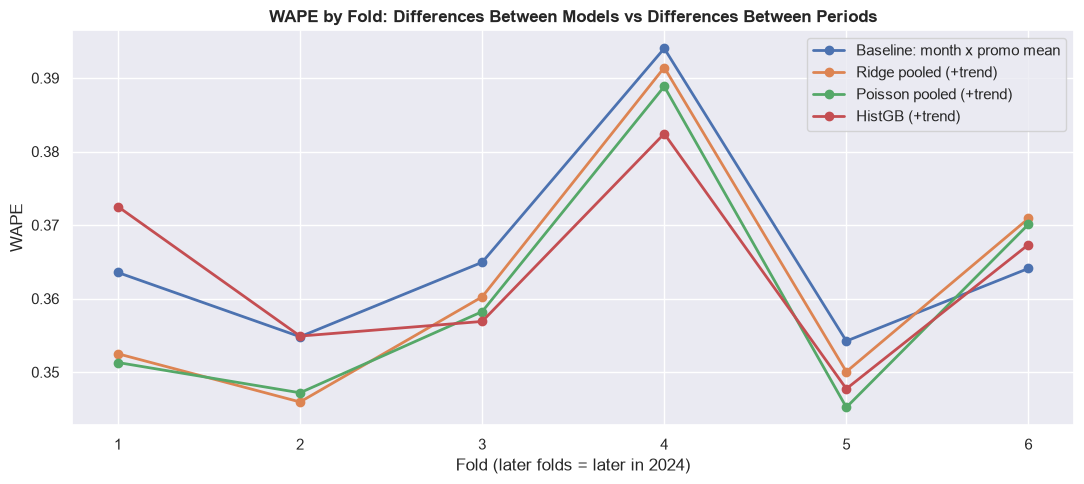

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
for name in [BASELINE, 'Ridge pooled (+trend)', 'Poisson pooled (+trend)', 'HistGB (+trend)']:
    ax.plot(cv_results[name]['fold'], cv_results[name]['WAPE'], marker='o', linewidth=2, label=name)
ax.set_xlabel('Fold (later folds = later in 2024)')
ax.set_ylabel('WAPE')
ax.set_title('WAPE by Fold: Differences Between Models vs Differences Between Periods', fontweight='bold')
ax.legend()
plt.tight_layout()
save_figure(fig, '02_wape_by_fold')
plt.show()

**Observations**
- Month and promotion carry almost all of the usable signal: the month x promotion baseline (MAE 27.1, WAPE 0.366) is already close to the best models, while ignoring them (product mean) is about 11% worse (MAE 30.1).
- Every reasonable model lands within about 2% of the baseline (MAE 26.7-27.2), far less than the spread between folds (std of MAE ≈ 5, see chart). Gains are small, and since models are selected and evaluated on the same folds, the ranking is indicative rather than conclusive.
- Trend: adding it lowers MAE (Poisson 26.97 to 26.68) and turns a systematic under-forecast (bias ≈ -6%) into a small over-forecast (≈ +3%). The estimated growth is unstable in early folds (15% per year, settling near 9%; 7% on all data), so it should not be extrapolated blindly beyond 2024.
- Confirmed EDA decisions: price and stock add nothing (Poisson MAE 26.680 vs 26.681; Ridge 26.786 vs 26.797), and a pooled model beats per-product models (Ridge 26.79 vs 27.24).
- Gradient boosting does no better than the baseline (27.15), so there is no sign of non-linear structure for it to exploit. The log-link Poisson model is slightly better than Ridge (26.68 vs 26.79), consistent with the multiplicative structure.
- Seasonal encoding: Fourier orders K=1-3 are equivalent (within 0.05 MAE; K=1 is nominally the lowest at 26.64, K=3 at 26.68) and all beat 11 month dummies (26.91). K=3 is kept as a mildly flexible choice that costs nothing in accuracy; K=1 would be the more parsimonious alternative, and the difference is far below the fold-to-fold noise.
- **Selected for the mean forecast: pooled Poisson GLM with trend.**

## 5. Probabilistic & Quantile Forecasting

EDA showed that **~73% of demand variance remains unexplained** after month and promotion effects, and Section 2.1 showed that the noise scales with the demand level. Inventory decisions (safety stock, service level) depend on the upper tail of demand, so we build quantile forecasts (P10, P50, P80, P90, P95) with five approaches:
1. **Additive residual quantiles**: Poisson mean + empirical quantiles of the training errors (a fixed spread).
2. **Multiplicative residual quantiles**: Poisson mean x empirical quantiles of the training ratio `actual / fitted` (spread grows with the level).
3. **Linear quantile regression**: one model per quantile on the same features.
4. **Log-linear quantile regression**: the same on `log(demand)`.
5. **Gradient boosting quantile**: one `HistGradientBoostingRegressor` per quantile.

Quantile crossings are repaired by sorting, and forecasts are clipped at zero. Metrics: pinball loss (`pinball_loss`) and empirical coverage (`interval_coverage`). For safety stock the key question is calibration: does P90 really cover about 90% of outcomes, in promotion and peak periods too?

In [10]:
Q_LABELS = [f"p{int(q * 100)}" for q in QUANTILES]
METHODS = ['Additive residual quantiles', 'Multiplicative residual quantiles',
           'Linear quantile regression', 'Log-linear quantile regression', 'Gradient boosting quantile']

def quantile_forecasts(tr, te):
    """Return {method: (n_test x len(QUANTILES) array)}, the Poisson mean forecast for the test rows, and extras."""
    glm = PoissonRegressor(alpha=1e-4, max_iter=1000).fit(X.loc[tr], y.loc[tr])
    mu_tr, mu_te = glm.predict(X.loc[tr]), glm.predict(X.loc[te])
    resid_tr = y.loc[tr].to_numpy() - mu_tr
    ratio_tr = y.loc[tr].to_numpy() / mu_tr

    out = {
        METHODS[0]: np.column_stack([mu_te + np.quantile(resid_tr, q) for q in QUANTILES]),
        METHODS[1]: np.column_stack([mu_te * np.quantile(ratio_tr, q) for q in QUANTILES]),
        METHODS[2]: np.column_stack([
            QuantileRegressor(quantile=q, alpha=0, solver='highs').fit(X.loc[tr], y.loc[tr]).predict(X.loc[te])
            for q in QUANTILES]),
        METHODS[3]: np.column_stack([
            np.exp(QuantileRegressor(quantile=q, alpha=0, solver='highs').fit(X.loc[tr], np.log(y.loc[tr])).predict(X.loc[te]))
            for q in QUANTILES]),
        METHODS[4]: np.column_stack([
            HistGradientBoostingRegressor(loss='quantile', quantile=q, **HGB_PARAMS).fit(X_tree.loc[tr], y.loc[tr]).predict(X_tree.loc[te])
            for q in QUANTILES]),
    }
    # Mean forecast for the LOOKAHEAD days after the test window, from the same fitted model
    # (no later information is used). Needed to cover multi-day lead times at the end of each fold.
    test_end = data.loc[te, 'date'].max()
    ext_idx = data.index[(data['date'] > test_end) & (data['date'] <= test_end + pd.Timedelta(days=LOOKAHEAD))]
    look = data.loc[ext_idx, ['date', 'product_id']].copy()
    look['demand_mean'] = glm.predict(X.loc[ext_idx]) if len(ext_idx) else np.array([])
    extras = {'ratio': ratio_tr, 'resid_std': resid_tr.std(), 'lookahead': look}

    return {m: np.clip(np.sort(v, axis=1), 0, None) for m, v in out.items()}, mu_te, extras

frames, ratio_rows, scale_rows, lookahead_frames = [], [], [], []
for fold, tr, te in splits:
    preds, mu_te, extras = quantile_forecasts(tr, te)
    ratio_rows.append(pd.DataFrame({'fold': fold, 'level': RATIO_LEVELS,
                                    'ratio': np.quantile(extras['ratio'], RATIO_LEVELS)}))
    scale_rows.append({'fold': fold, 'resid_std': extras['resid_std'], 'ratio_std': extras['ratio'].std()})
    lookahead_frames.append(extras['lookahead'].assign(fold=fold))
    base = data.loc[te, ['date', 'product_id', 'promotion', 'demand']].rename(columns={'demand': 'actual'})
    base['fold'], base['month'], base['mu'] = fold, cal.loc[te, 'month'].to_numpy(), mu_te
    for method, arr in preds.items():
        f = base.copy()
        f['method'] = method
        f[Q_LABELS] = arr
        frames.append(f)

oof = pd.concat(frames, ignore_index=True)
print(f"Out-of-fold quantile forecasts: {oof['method'].nunique()} methods x {len(oof) // oof['method'].nunique()} rows")

Out-of-fold quantile forecasts: 5 methods x 1800 rows


In [11]:
def evaluate_quantiles(df):
    rows = []
    for method in METHODS:
        g = df[df['method'] == method]
        row = {'method': method}
        for q, lab in zip(QUANTILES, Q_LABELS):
            row[f'pinball {lab.upper()}'] = pinball_loss(g['actual'], g[lab], q)
        row['pinball mean'] = np.mean([row[f'pinball {l.upper()}'] for l in Q_LABELS])
        for lab in ('p80', 'p90', 'p95'):
            row[f'coverage {lab.upper()}'] = np.mean(g['actual'] <= g[lab])
        row['coverage P10-P90'] = interval_coverage(g['actual'], g['p10'], g['p90'])
        rows.append(row)
    return pd.DataFrame(rows).set_index('method')

quantile_summary = evaluate_quantiles(oof)
quantile_summary.round(3)

,pinball P10,pinball P50,pinball P80,pinball P90,pinball P95,pinball mean,coverage P80,coverage P90,coverage P95,coverage P10-P90
method,,,,,,,,,,
Additive residual quantiles,5.779,13.346,8.817,5.323,3.033,7.260,0.806,0.896,0.943,0.761
Multiplicative residual quantiles,5.112,13.350,8.664,5.073,2.829,7.006,0.805,0.913,0.961,0.794
Linear quantile regression,5.110,13.510,8.785,5.118,2.852,7.075,0.834,0.919,0.959,0.811
Log-linear quantile regression,5.116,13.459,8.689,5.038,2.784,7.017,0.814,0.910,0.954,0.804
Gradient boosting quantile,5.150,13.740,9.038,5.579,3.484,7.398,0.781,0.884,0.932,0.771


,All days,Promotion days,No-promotion days,Peak months (Mar-May),Trough months (Aug-Oct)
method,,,,,
Additive residual quantiles,0.896,0.834,0.912,0.813,0.959
Multiplicative residual quantiles,0.913,0.942,0.905,0.907,0.889
Linear quantile regression,0.919,0.909,0.922,0.876,0.950
Log-linear quantile regression,0.910,0.914,0.909,0.883,0.917
Gradient boosting quantile,0.884,0.829,0.898,0.880,0.930


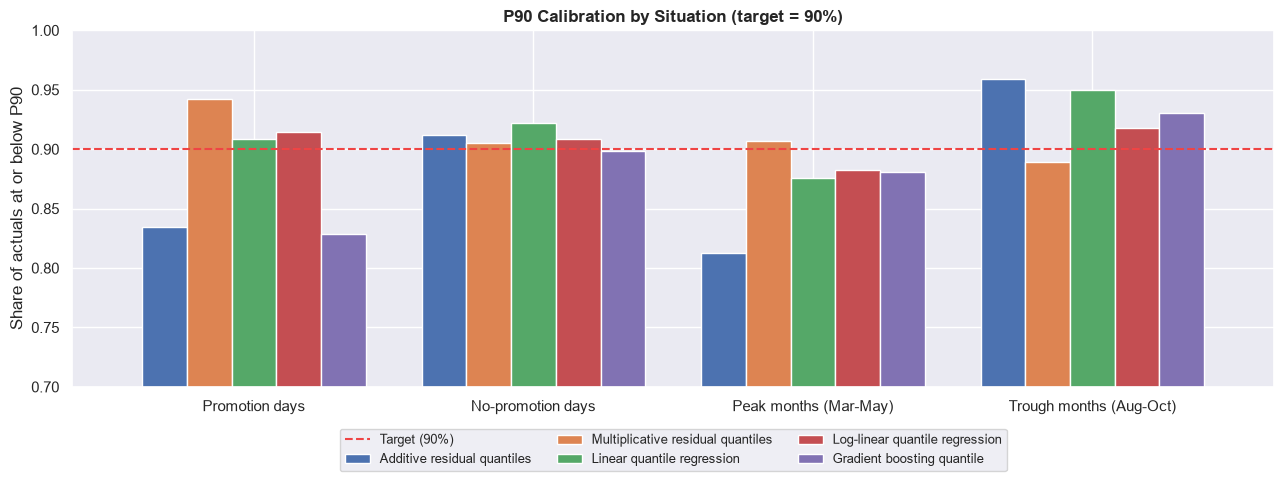

In [12]:
# Calibration of P90 in the situations that matter for safety stock
def p90_coverage_by_group(df):
    rows = []
    for method in METHODS:
        g = df[df['method'] == method]
        hit = g['actual'] <= g['p90']
        rows.append({
            'method': method,
            'All days': hit.mean(),
            'Promotion days': hit[g['promotion'] == 1].mean(),
            'No-promotion days': hit[g['promotion'] == 0].mean(),
            'Peak months (Mar-May)': hit[g['month'].isin([3, 4, 5])].mean(),
            'Trough months (Aug-Oct)': hit[g['month'].isin([8, 9, 10])].mean(),
        })
    return pd.DataFrame(rows).set_index('method')

calibration = p90_coverage_by_group(oof)
display(calibration.round(3))

fig, ax = plt.subplots(figsize=(13, 5))
calibration.drop(columns='All days').T.plot(kind='bar', ax=ax, width=0.8)
ax.axhline(0.90, color='#ef4444', linestyle='--', linewidth=1.5, label='Target (90%)')
ax.set_ylim(0.7, 1.0)
ax.set_ylabel('Share of actuals at or below P90')
ax.set_title('P90 Calibration by Situation (target = 90%)', fontweight='bold')
ax.tick_params(axis='x', rotation=0)
ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
save_figure(fig, '02_quantile_calibration')
plt.show()

**Observations**
- Multiplicative residual quantiles achieve the lowest mean pinball loss (7.01 vs 7.26 for additive). Log-linear quantile regression is essentially tied (7.02), linear quantile regression is slightly worse (7.08), and gradient boosting is the weakest (7.41) and under-covers (P90 88%, P95 93%).
- Calibration is what matters for safety stock. The additive (fixed-spread) approach under-covers where demand is high: P90 covers only 83% of promotion days and 81% of peak-month days, but 96% in the trough months. A fixed buffer is too small when demand is high and too large when it is low.
- Multiplicative quantiles are much more even: P90 covers 94% (promotion), 91% (no promotion), 91% (peak) and 89% (trough). Overall coverage is 91% for P90 and 96% for P95, slightly conservative.
- **Selected for uncertainty: multiplicative residual quantiles.** Best or tied-best loss, most even calibration, and simple to explain: each quantile is the mean forecast times a fixed factor.

## 6. Model Comparison & Diagnostic Analysis

We carry forward the pooled Poisson GLM (with trend) for the mean and multiplicative residual quantiles for the uncertainty.

In [13]:
FINAL_POINT = 'Poisson pooled (+trend)'
FINAL_METHOD = 'Multiplicative residual quantiles'

scorecard = summarize([BASELINE, FINAL_POINT])[['MAE', 'MAE (std across folds)', 'RMSE', 'WAPE', 'Bias', 'Folds better than baseline']]
scorecard.round(3)

,MAE,MAE (std across folds),RMSE,WAPE,Bias,Folds better than baseline
model,,,,,,
Baseline: month x promo mean,27.137,5.112,32.337,0.366,-0.062,0
Poisson pooled (+trend),26.680,4.865,31.865,0.360,0.029,5


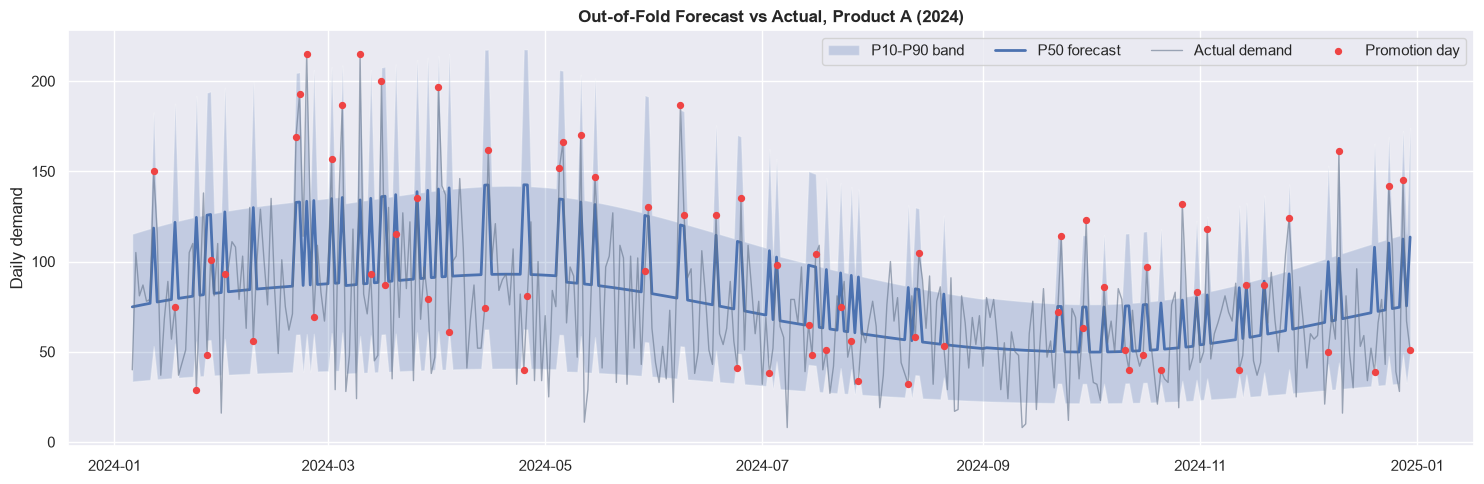

In [14]:
final = oof[oof['method'] == FINAL_METHOD].sort_values(['product_id', 'date']).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 5))
g = final[final['product_id'] == 'A']
ax.fill_between(g['date'], g['p10'], g['p90'], alpha=0.25, label='P10-P90 band')
ax.plot(g['date'], g['p50'], linewidth=2, label='P50 forecast')
ax.plot(g['date'], g['actual'], color='#64748b', alpha=0.6, linewidth=1, label='Actual demand')
promo = g[g['promotion'] == 1]
ax.scatter(promo['date'], promo['actual'], color='#ef4444', s=18, zorder=3, label='Promotion day')
ax.set_title('Out-of-Fold Forecast vs Actual, Product A (2024)', fontweight='bold')
ax.set_ylabel('Daily demand')
ax.legend(ncol=4, loc='upper right')
plt.tight_layout()
save_figure(fig, '02_actual_vs_forecast')
plt.show()

In [15]:
# Residual diagnostics on out-of-fold forecasts
final = final.assign(resid=final['actual'] - final['p50'])
n_days = final.groupby('product_id').size().iloc[0]
n_prod = final['product_id'].nunique()
band_one = 1.96 / np.sqrt(n_days)             # approx. 95% band for ONE product's autocorrelation
band_mean = band_one / np.sqrt(n_prod)        # ... for the mean of n_prod independent products

lags = list(range(1, 31))
acf = pd.DataFrame({pid: [g['resid'].autocorr(l) for l in lags] for pid, g in final.groupby('product_id')}, index=lags)
n_out = int((acf.abs() > band_one).sum().sum())
print(f"Residual autocorrelation (single-product 95% band +/-{band_one:.3f}; band for the 5-product mean +/-{band_mean:.3f})")
print(acf.loc[[1, 2, 7, 30]].assign(mean=lambda d: d.mean(axis=1)).round(3).to_string())
print(f"\n|r| beyond the single-product band: {n_out} of {acf.size} (lags 1-30 x {n_prod} products); about {0.05 * acf.size:.1f} expected by chance")
print(f"Mean-over-products |r| beyond its band: {int((acf.mean(axis=1).abs() > band_mean).sum())} of {len(lags)} lags")

print("\nQuantile forecast relative to the mean forecast (min - max across rows):")
for lab in ('p10', 'p50', 'p90', 'p95'):
    ratio = final[lab] / final['mu']
    print(f"  {lab.upper()}: {ratio.min():.2f} - {ratio.max():.2f}")

by_fold = final.groupby('fold').apply(
    lambda g: pd.Series({'P90 coverage': (g['actual'] <= g['p90']).mean(),
                         'P95 coverage': (g['actual'] <= g['p95']).mean()}),
    include_groups=False)
by_fold.round(3)

Residual autocorrelation (single-product 95% band +/-0.103; band for the 5-product mean +/-0.046)
        A      B      C      D      E   mean
1  -0.018  0.064 -0.029  0.006 -0.078 -0.011
2  -0.039  0.099 -0.091  0.023  0.035  0.006
7   0.007  0.072  0.039 -0.080 -0.007  0.006
30 -0.017  0.035  0.149 -0.046 -0.128 -0.001

|r| beyond the single-product band: 15 of 150 (lags 1-30 x 5 products); about 7.5 expected by chance
Mean-over-products |r| beyond its band: 1 of 30 lags

Quantile forecast relative to the mean forecast (min - max across rows):
  P10: 0.44 - 0.45
  P50: 1.00 - 1.01
  P90: 1.54 - 1.55
  P95: 1.64 - 1.65


,P90 coverage,P95 coverage
fold,,
1,0.950,0.990
2,0.903,0.957
3,0.913,0.970
4,0.887,0.930
5,0.897,0.950
6,0.927,0.967


**Observations**
- Little structure is left in the errors. The residual autocorrelation averaged over the five products is about 0 at lags 1, 2, 7 and 30 and lies inside its approximate 95% band (±0.046) at 29 of 30 lags, consistent with the EDA conclusion that lag features add little. Per product the picture is slightly noisier: 15 of 150 product-lag values exceed the single-product band (±0.10) against about 7 expected by chance, with the largest at lag 30 (product C +0.15, product E -0.13). These are small, differ in sign and do not repeat across products, so they do not justify lag features, but "exactly zero" would overstate it. (A lag-based model was not cross-validated; at a 60-day horizon recent lags are unavailable for most of the window anyway.)
- Coverage is stable across folds: P90 between 88.7% and 95.0% and P95 between 93.0% and 99.0%. With 300 observations per fold, deviations of about 2 percentage points are sampling noise. Fold 1, with the shortest training window (370 days), is the most conservative.
- The mean forecast improves WAPE only modestly over the baseline (0.366 to 0.360) but removes its systematic under-forecast (bias -6% to +3%). The trend term therefore leaves a small **over**-forecast of about 3%, which will show up as slightly higher inventory downstream.
- The multiplicative quantile forecasts are the mean forecast times fixed factors (P10, P90 and P95 are about 0.45x, 1.55x and 1.65x). That is how the method is built, so it shows what the method does rather than validating it; the validation is the calibration by situation in Section 5, where the buffers do scale with the demand level (larger in peak season and on promotion days).
- Caveats: only two years of data, the same folds are used for selection and evaluation, and the trend is not extrapolated beyond 2024. The export therefore contains out-of-fold forecasts for 2024 only.


## 7. Export Forecasts for Inventory Optimization

The export contains the out-of-fold forecasts for 2024 (made without seeing the days they forecast), so the inventory notebook can replay real demand against them:
- `date`, `product_id`, `fold`, `promotion`, `actual_demand`
- `demand_mean` (Poisson point forecast)
- `demand_p10`, `demand_p50`, `demand_p80`, `demand_p90`, `demand_p95` (quantiles for cycle stock and safety stock sizing)

Output is saved at `outputs/csv/demand_forecasts.csv`.

Three supporting files let the inventory notebook build the demand distribution over a multi-day lead time (daily quantiles cannot simply be added up):
- `ratio_quantiles.csv`: for each fold, the 1%-99% quantiles of `actual / fitted` in the training window (the multiplicative noise distribution).
- `training_error_scale.csv`: for each fold, the standard deviation of the additive training error (`resid_std`, used by the classical constant-sigma benchmark) and the standard deviation of the ratio `actual / fitted` (`ratio_std`, i.e. the coefficient of variation, used by the level-proportional benchmark).
- `mean_forecast_lookahead.csv`: the mean forecast for the 21 days after each test window, from the same fold's model.

In [16]:
export = final[['date', 'product_id', 'fold', 'promotion', 'actual', 'mu'] + Q_LABELS].rename(
    columns={'actual': 'actual_demand', 'mu': 'demand_mean', **{l: f'demand_{l}' for l in Q_LABELS}})

# Sanity checks before saving
assert len(export) == N_FOLDS * HORIZON * data['product_id'].nunique()
assert not export.isna().any().any()
assert (export[[f'demand_{l}' for l in Q_LABELS]].diff(axis=1).iloc[:, 1:] >= 0).all().all()   # quantiles non-decreasing

path = save_output(export, 'demand_forecasts')
ratio_quantiles = pd.concat(ratio_rows, ignore_index=True)
error_scale = pd.DataFrame(scale_rows)
lookahead = pd.concat(lookahead_frames, ignore_index=True)[['fold', 'date', 'product_id', 'demand_mean']]
save_output(ratio_quantiles, 'ratio_quantiles')
save_output(error_scale, 'training_error_scale')
save_output(lookahead, 'mean_forecast_lookahead')
save_output(point_summary.reset_index(), 'point_model_comparison')
save_output(quantile_summary.join(calibration, rsuffix=' (P90 cov.)').reset_index(), 'quantile_method_comparison')
print(f"Saved {len(export)} rows to {path.relative_to(path.parents[1])}")
export.head()

Saved 1800 rows to csv\demand_forecasts.csv


,date,product_id,fold,promotion,actual_demand,demand_mean,demand_p10,demand_p50,demand_p80,demand_p90,demand_p95
0,2024-01-06,A,1,0,40,74.751787,33.573097,74.895597,103.286544,115.342423,123.152106
1,2024-01-07,A,1,0,105,75.155297,33.754324,75.299883,103.844084,115.965041,123.816880
2,2024-01-08,A,1,0,81,75.552343,33.932648,75.697693,104.392693,116.577685,124.471005
3,2024-01-09,A,1,0,87,75.942728,34.107981,76.088829,104.932098,117.180051,125.114157
4,2024-01-10,A,1,0,78,76.326272,34.280241,76.473110,105.462051,117.771861,125.746038


---
### Next Notebook
Proceed to inventory policy simulation and safety stock optimization in: **`notebooks/inventory_optimization.ipynb`**